In [2]:
import numpy as np

def allpass_time_varying(x, a):
    N = len(x)
    y = np.zeros(N)

    for n in range(N):
        if n == 0:
            x_prev = 0
            y_prev = 0
        else:
            x_prev = x[n-1]
            y_prev = y[n-1]

        y[n] = -a[n] * x[n] + x_prev + a[n] * y_prev

    return y



In [7]:
#2. Ghép chuỗi 4 tầng Allpass và dùng LFO quét tần số cắt từ 200 Hz đến 3500 Hz với tốc độ 0.4 Hz.

def phaser_4stage(x, fs):
    N = len(x)
    n = np.arange(N)

    f_min = 200       
    f_max = 3500      
    f_lfo = 0.4       

    f0 = (f_min + f_max)/2 + \
         (f_max - f_min)/2 * np.sin(
             2*np.pi*f_lfo*n/fs
         )

    omega0 = 2*np.pi*f0/fs

    ap = (np.tan(omega0/2) - 1) / \
         (np.tan(omega0/2) + 1)


    y1 = allpass_time_varying(x, ap)
    y2 = allpass_time_varying(y1, ap)
    y3 = allpass_time_varying(y2, ap)
    y4 = allpass_time_varying(y3, ap)

    return y4, f0



Tần số nhỏ nhất: 200.00000066987923 Hz
Tần số lớn nhất: 3499.9999993301208 Hz


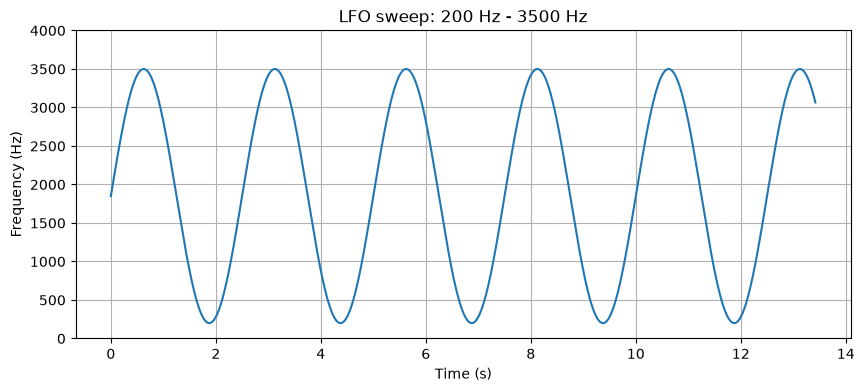

Đã xuất file: guitar_phaser.wav


In [6]:
from scipy.io.wavfile import read

fs, x = read("guitar1.wav")

x = x.astype(float)

if x.ndim == 2:
    x = np.mean(x, axis=1)

x = x / np.max(np.abs(x))


y4AP, f0 = phaser_4stage(x, fs)

print("Tần số nhỏ nhất:", np.min(f0), "Hz")
print("Tần số lớn nhất:", np.max(f0), "Hz")

import matplotlib.pyplot as plt

t = np.arange(len(f0)) / fs

plt.figure(figsize=(10, 4))
plt.plot(t, f0)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("LFO sweep: 200 Hz - 3500 Hz")

plt.ylim(0, 4000)
plt.grid()
plt.show()

y_phaser = 0.5 * x + 0.5 * y4AP

y_phaser = y_phaser / np.max(np.abs(y_phaser))


# nghe
from IPython.display import Audio, display

display(Audio(y_phaser, rate=fs))



from scipy.io.wavfile import write

y_int16 = np.int16(y_phaser * 32767)

write("guitar_phaser.wav", fs, y_int16)

print("Đã xuất file: guitar_phaser.wav")